# 第193章: エネルギーベースモデルの定式化 — 分配関数という壁

## Energy-Based Models and the Partition Function

---

### このノートブックの位置づけ

190-191 で**正規化フロー**を作りました。あれは「可逆な変換で基底分布を変形する」
という方針で、厳密な尤度を得るために**アーキテクチャに強い制約**をかけました。

| 制約 | 191 での代償 |
|---|---|
| 各層が可逆 | 層の形がカップリングに限定される |
| 次元を変えられない | 高次元で重い（$d=196$ で 174万パラメータ） |
| $\log\lvert\det J\rvert$ が安くないといけない | 表現力を左下ブロックに押し込む設計 |

**エネルギーベースモデル（EBM）は逆の方針を取ります。** 制約を全部捨てて、
**任意のスカラー関数** $E_\theta(x)$ ひとつでモデルを定義します。

$$p_\theta(x) = \frac{e^{-E_\theta(x)}}{Z_\theta}, \qquad
Z_\theta = \int e^{-E_\theta(x)}\,dx$$

$E_\theta$ はどんなニューラルネットでも構いません。可逆性も、ヤコビアンも、
次元の保存も要りません。**これ以上に自由なモデルはありません。**

代償は1つだけ、しかし致命的です。**分母 $Z_\theta$ が計算できません。**

本章は $Z$ という壁の正体を**測って**確かめ、「それでも何ができるか」を整理します。
結論を先に言うと、$Z$ が消える量が2つあり — **密度比**と**スコア** $\nabla_x \log p$ —
この2つが 194（ランジュバン）と 195（スコアマッチングと拡散の統合）の土台になります。

### 学習目標

- [ ] $p \propto e^{-E}$ を定義し、$E$ の定数シフトが分布を変えないことを確認できる
- [ ] 格子で $Z$ を計算するコストが $K^d$ で爆発することを**実測**できる
- [ ] 重点サンプリングによる $Z$ 推定が次元とともに壊れることを**有効サンプル数**で示せる
- [ ] $Z$ を知らなくても計算できる量（密度比・スコア）を挙げ、数値で確認できる
- [ ] 最尤学習の勾配 $\nabla_\theta \mathrm{NLL} = \nabla_\theta E(x_{\text{data}}) - \mathbb{E}_{p_\theta}[\nabla_\theta E]$ を導出できる
- [ ] 負の項を落とすと**崩壊する**ことを測定できる
- [ ] 2次元で厳密な最尤学習を実行し、フロー（191）と比べられる

### 前提知識

| ノートブック | トピック |
|---|---|
| 31 | 最尤推定 |
| 33 | 混合ガウスモデル（本章の目標分布） |
| **190-191** | **正規化フロー（本章が対比する相手）** |
| 47 | logsumexp（$\log Z$ の計算に必須） |
| 34 | EM / ELBO（「扱いにくい正規化定数」の既出例） |

**難易度**: ★★★★☆ | **所要時間**: 150-180分

> ⏱ **実行時間**: CPU で約25秒です。

## 目次

1. [環境セットアップ](#setup)
2. [エネルギー関数と分配関数](#energy)
3. [分配関数の壁](#wall)
4. [Z を知らなくても計算できること](#without-z)
5. [最尤学習の勾配と「負のサンプル」](#training)
6. [2次元で厳密な最尤学習をする](#exact)
7. [まとめとチートシート](#summary)
8. [自己評価クイズ](#quiz)

<a id="setup"></a>
## 1. 環境セットアップ

In [1]:
# ============================================================
# 環境セットアップ
# ============================================================

import math
import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("torch:", torch.__version__)
print("numpy:", np.__version__)

torch: 2.9.1
numpy: 2.2.6


<a id="energy"></a>
## 2. エネルギー関数と分配関数

### 定義

スカラー関数 $E_\theta: \mathbb{R}^d \to \mathbb{R}$（**エネルギー**）に対して

$$p_\theta(x) = \frac{e^{-E_\theta(x)}}{Z_\theta}, \qquad
Z_\theta = \int e^{-E_\theta(x)}\,dx$$

符号が負なのは物理の慣習です。**エネルギーが低い場所ほど確率が高い**。
$e^{-E} > 0$ なので密度は自動的に非負で、$Z$ で割れば積分が 1 になります。
$E$ に要求されるのは「$Z$ が有限になるくらい十分速く増大すること」だけです。

### 定数シフトの不変性

$E \to E + c$ とすると、$e^{-E-c} = e^{-c}e^{-E}$ なので $Z \to e^{-c} Z$ となり、
**比が変わらないので分布は同一**です。

$$\frac{e^{-E(x)-c}}{e^{-c}Z} = \frac{e^{-E(x)}}{Z}$$

これは「$E$ の絶対値には意味がなく、**差にしか意味がない**」ということです。
ニューラルネットの出力に定数バイアスが乗っても分布は変わりません。
逆に言えば、**$E$ の値を見ても分布が良いかは分からない**。この性質は
第5節で「崩壊」を診断するときに効いてきます。

1次元の二重井戸 $E(x) = \frac{1}{4}x^4 - \frac{3}{2}x^2$ で確かめます。

In [2]:
# ============================================================
# エネルギーは定数シフトで不変
# ============================================================

def energy_1d(x, c=0.0):
    # 二重井戸ポテンシャル。x = +-sqrt(3) に2つの谷がある
    return 0.25 * x**4 - 1.5 * x**2 + c

xs = torch.linspace(-6, 6, 20001)
dx = float(xs[1] - xs[0])

shift_rows = []
for c in [0.0, 100.0, -37.5]:
    e = energy_1d(xs, c)
    # log Z を logsumexp で安定に計算する（47 章の logsumexp）
    log_Z = torch.logsumexp(-e, 0) + math.log(dx)
    p = torch.exp(-e - log_Z)
    integral = float(p.sum() * dx)
    p_at_0 = float(p[len(p) // 2])
    shift_rows.append((c, float(log_Z), integral, p_at_0))
    print(f"c = {c:+7.1f}:  log Z = {float(log_Z):+10.4f}   "
          f"∫p dx = {integral:.6f}   p(0) = {p_at_0:.6f}")

print()
print("-> log Z は c に応じてぴったり -c だけ動くが、密度 p(0) は完全に同一。")
print("   E の絶対値には意味がなく、差にしか意味がない。")

e0 = energy_1d(xs)
log_Z0 = torch.logsumexp(-e0, 0) + math.log(dx)
p0 = torch.exp(-e0 - log_Z0)
print()
x_argmax = float(xs[int(torch.argmax(p0))])
print(f"谷の位置（解析）: x = +-sqrt(3) = +-{math.sqrt(3):.4f}")
print(f"密度の最大点（数値）: x = {x_argmax:+.4f}（左右対称なので argmax は左側を返す）")
print(f"絶対値で比較: |x| = {abs(x_argmax):.4f} vs sqrt(3) = {math.sqrt(3):.4f}")

c =    +0.0:  log Z =    +3.0781   ∫p dx = 1.000001   p(0) = 0.046047
c =  +100.0:  log Z =   -96.9219   ∫p dx = 0.999999   p(0) = 0.046047
c =   -37.5:  log Z =   +40.5781   ∫p dx = 0.999999   p(0) = 0.046047

-> log Z は c に応じてぴったり -c だけ動くが、密度 p(0) は完全に同一。
   E の絶対値には意味がなく、差にしか意味がない。

谷の位置（解析）: x = +-sqrt(3) = +-1.7321
密度の最大点（数値）: x = -1.7322（左右対称なので argmax は左側を返す）
絶対値で比較: |x| = 1.7322 vs sqrt(3) = 1.7321


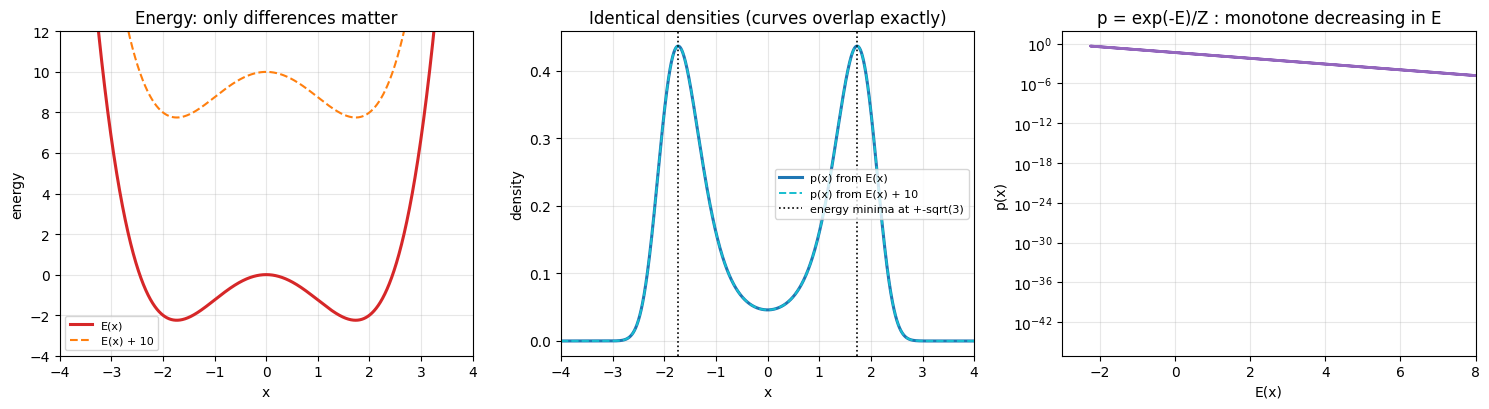

In [3]:
# ============================================================
# 図: エネルギーと密度
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].plot(xs, e0, lw=2.2, color="tab:red", label="E(x)")
axes[0].plot(xs, energy_1d(xs, 10.0), lw=1.5, ls="--", color="tab:orange",
             label="E(x) + 10")
axes[0].set_xlim(-4, 4)
axes[0].set_ylim(-4, 12)
axes[0].set_xlabel("x")
axes[0].set_ylabel("energy")
axes[0].set_title("Energy: only differences matter")
axes[0].legend(fontsize=8)

axes[1].plot(xs, p0, lw=2.2, color="tab:blue", label="p(x) from E(x)")
axes[1].plot(xs, torch.exp(-energy_1d(xs, 10.0)
                           - (torch.logsumexp(-energy_1d(xs, 10.0), 0) + math.log(dx))),
             lw=1.4, ls="--", color="tab:cyan", label="p(x) from E(x) + 10")
axes[1].axvline(math.sqrt(3), color="k", ls=":", lw=1.2)
axes[1].axvline(-math.sqrt(3), color="k", ls=":", lw=1.2,
                label="energy minima at +-sqrt(3)")
axes[1].set_xlim(-4, 4)
axes[1].set_xlabel("x")
axes[1].set_ylabel("density")
axes[1].set_title("Identical densities (curves overlap exactly)")
axes[1].legend(fontsize=8)

# エネルギーと密度の対応（低いエネルギー = 高い確率）
axes[2].plot(e0, p0, lw=2, color="tab:purple")
axes[2].set_xlim(-3, 8)
axes[2].set_xlabel("E(x)")
axes[2].set_ylabel("p(x)")
axes[2].set_title("p = exp(-E)/Z : monotone decreasing in E")
axes[2].set_yscale("log")

plt.tight_layout()
plt.show()

### 読み取れること

- `log Z` は $c$ ちょうどぶん動くのに、密度 $p(0) = 0.046047$ は **3つの $c$ で完全に同一**でした。
  中央の図で2本の曲線は完全に重なっています。
- 密度の最大点は数値で $x = -1.7322$、エネルギーの極小は解析で $x = \pm\sqrt{3} = \pm 1.7321$。
  一致します（分布は左右対称なので $\pm\sqrt{3}$ の両方が最大。`argmax` は左側を返す）。
  **エネルギーの谷が確率の山**です。
- 右の図は $p = e^{-E}/Z$ の単調性です。$E$ が低いほど $p$ が高い、以外のことは起きません。
  EBM の表現力は全部「$E$ の形をどう作るか」に入っています。

> 💡 **なぜこの形が自然か**: 分布を「スカラー関数ひとつ」で表せるので、
> ニューラルネットの出力が**1次元**で済みます。フローは $d$ 次元の全単射を作る
> 必要があり、VAE はエンコーダとデコーダの2本が必要でした。
> **モデルの設計としては EBM が最も単純**です。難しさは全部 $Z$ に移っています。

<a id="wall"></a>
## 3. 分配関数の壁

$Z_\theta = \int e^{-E_\theta(x)}\,dx$ は $d$ 次元の積分です。
3つの方法を試して、どこで壊れるかを測ります。

| 方法 | コスト | 本節の結果 |
|---|---|---|
| 格子で総当たり | $K^d$ | $d=4$ で 100 MB、$d=5$ で実行不能 |
| 重点サンプリング | 一定だが**分散**が爆発 | $d=40$ で有効サンプル数 1.5 |
| 解析積分 | $E$ が特別な形のときだけ | ガウス（$E$ が2次式）など |

### 格子で総当たりする

In [4]:
# ============================================================
# 格子で log Z を計算するコスト: K^d
# ============================================================

def energy_sep(X):
    # 分離可能な二重井戸（各次元に同じ井戸）。
    # 分離可能なら本当は1次元の積で済むが、一般の E ではそれができないので、
    # ここでは「一般の E を格子で総当たりする」コストを測る
    return (0.25 * X**4 - 1.5 * X**2).sum(-1)

K_GRID = 50
grid_rows = []
for d in [1, 2, 3, 4, 5]:
    n_points = K_GRID**d
    if n_points > 6e7:
        print(f"d={d}: 格子点 {n_points:,} -> 実行せず（メモリが足りない）")
        grid_rows.append((d, n_points, None, n_points * d * 4 / 1e6))
        continue
    t0 = time.time()
    g = torch.linspace(-4, 4, K_GRID)
    mesh = torch.meshgrid(*([g] * d), indexing="ij")
    X = torch.stack([t.reshape(-1) for t in mesh], -1)
    e = energy_sep(X)
    log_Z_d = torch.logsumexp(-e, 0) + d * math.log(float(g[1] - g[0]))
    elapsed = time.time() - t0
    mem = X.numel() * 4 / 1e6
    grid_rows.append((d, n_points, elapsed, mem))
    print(f"d={d}: 格子点 {n_points:>12,}  {elapsed:6.2f}s  "
          f"log Z = {float(log_Z_d):+9.4f}  メモリ {mem:7.1f} MB")
    del X, mesh, e

print()
d_mnist = 196
print(f"参考: d={d_mnist}（MNIST 14x14、191 で使った次元）なら")
print(f"      {K_GRID}^{d_mnist} = 10^{d_mnist * math.log10(K_GRID):.0f} 点。")
print(f"      観測可能な宇宙の原子数は 10^80 程度。比較の対象にならない。")

d=1: 格子点           50    0.00s  log Z =   +3.0783  メモリ     0.0 MB
d=2: 格子点        2,500    0.00s  log Z =   +6.1567  メモリ     0.0 MB
d=3: 格子点      125,000    0.00s  log Z =   +9.2350  メモリ     1.5 MB
d=4: 格子点    6,250,000    0.08s  log Z =  +12.3133  メモリ   100.0 MB
d=5: 格子点 312,500,000 -> 実行せず（メモリが足りない）

参考: d=196（MNIST 14x14、191 で使った次元）なら
      50^196 = 10^333 点。
      観測可能な宇宙の原子数は 10^80 程度。比較の対象にならない。


In [5]:
# ============================================================
# 重点サンプリングで log Z を推定する（有効サンプル数を見る）
# ============================================================

# 真の log Z: 分離可能なので 1次元の値の d 倍
e1 = 0.25 * xs**4 - 1.5 * xs**2
log_Z_1d = float(torch.logsumexp(-e1, 0) + math.log(dx))
print(f"1次元の真の log Z = {log_Z_1d:+.4f}（分離可能なので d 次元では d 倍）")
print()

def log_Z_importance(d, n=200_000, prop_sd=2.0, seed=0):
    # 提案分布 q = N(0, prop_sd^2 I) から引いて重み w = exp(-E)/q を平均する
    gen = torch.Generator().manual_seed(seed)
    x = torch.randn(n, d, generator=gen) * prop_sd
    log_q = (-0.5 * (x / prop_sd) ** 2 - math.log(prop_sd)
             - 0.5 * math.log(2 * math.pi)).sum(-1)
    log_w = -energy_sep(x) - log_q
    log_Z_est = torch.logsumexp(log_w, 0) - math.log(n)
    # 有効サンプル数 ESS = (sum w)^2 / sum w^2。重みが1点に集中すると 1 に落ちる
    ess = float(torch.exp(2 * torch.logsumexp(log_w, 0) - torch.logsumexp(2 * log_w, 0)))
    return float(log_Z_est), ess

is_rows = []
for d in [1, 2, 5, 10, 20, 40]:
    est, ess = log_Z_importance(d)
    truth = d * log_Z_1d
    is_rows.append((d, est, truth, ess))
    print(f"d={d:3d}: 推定 {est:+10.4f}  真値 {truth:+10.4f}  "
          f"誤差 {est - truth:+8.4f}  有効サンプル数 {ess:9.1f} / 200000")

print()
print("-> 誤差が常に負（過小推定）。重みの最大値に支配され、裾を取りこぼすため。")
print("   log Z を過小推定すると、尤度を過大評価することになる（危険な方向）。")

1次元の真の log Z = +3.0781（分離可能なので d 次元では d 倍）

d=  1: 推定    +3.0799  真値    +3.0781  誤差  +0.0018  有効サンプル数   95578.7 / 200000
d=  2: 推定    +6.1542  真値    +6.1562  誤差  -0.0020  有効サンプル数   45631.7 / 200000
d=  5: 推定   +15.3764  真値   +15.3905  誤差  -0.0141  有効サンプル数    5191.6 / 200000
d= 10: 推定   +30.6882  真値   +30.7810  誤差  -0.0928  有効サンプル数     192.0 / 200000
d= 20: 推定   +60.7159  真値   +61.5620  誤差  -0.8461  有効サンプル数       8.6 / 200000


d= 40: 推定  +115.9077  真値  +123.1240  誤差  -7.2163  有効サンプル数       1.5 / 200000

-> 誤差が常に負（過小推定）。重みの最大値に支配され、裾を取りこぼすため。
   log Z を過小推定すると、尤度を過大評価することになる（危険な方向）。


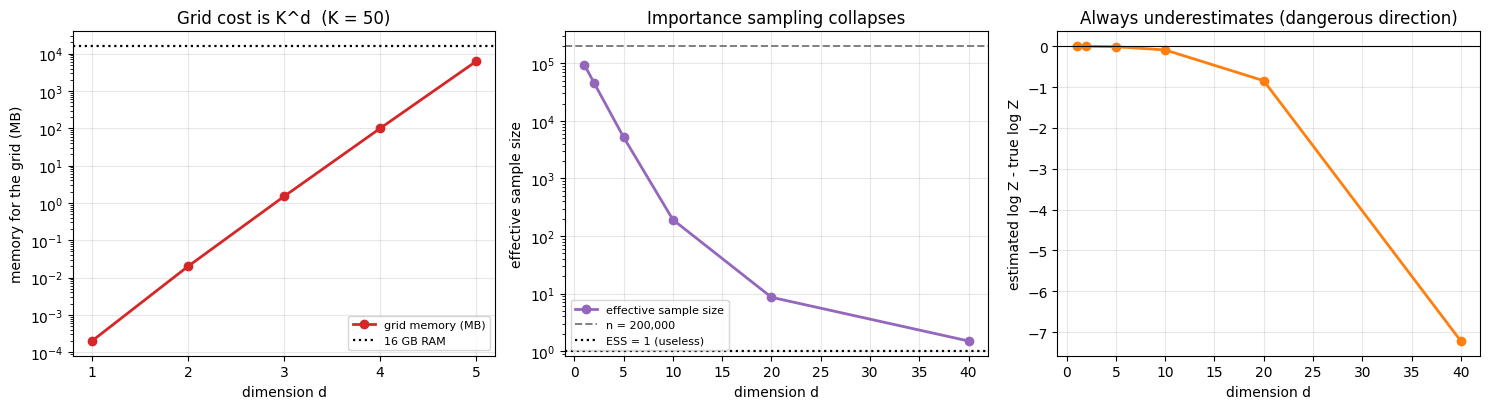

In [6]:
# ============================================================
# 図: 分配関数の壁
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ds_grid = [r[0] for r in grid_rows]
mems = [r[3] for r in grid_rows]
axes[0].semilogy(ds_grid, mems, "o-", lw=2, color="tab:red", label="grid memory (MB)")
axes[0].axhline(16_000, color="k", ls=":", lw=1.6, label="16 GB RAM")
axes[0].set_xlabel("dimension d")
axes[0].set_ylabel("memory for the grid (MB)")
axes[0].set_title(f"Grid cost is K^d  (K = {K_GRID})")
axes[0].set_xticks(ds_grid)
axes[0].legend(fontsize=8)

ds_is = [r[0] for r in is_rows]
axes[1].semilogy(ds_is, [r[3] for r in is_rows], "o-", lw=2, color="tab:purple",
                 label="effective sample size")
axes[1].axhline(200_000, color="tab:gray", ls="--", lw=1.4, label="n = 200,000")
axes[1].axhline(1.0, color="k", ls=":", lw=1.6, label="ESS = 1 (useless)")
axes[1].set_xlabel("dimension d")
axes[1].set_ylabel("effective sample size")
axes[1].set_title("Importance sampling collapses")
axes[1].legend(fontsize=8)

axes[2].plot(ds_is, [r[1] - r[2] for r in is_rows], "o-", lw=2, color="tab:orange")
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_xlabel("dimension d")
axes[2].set_ylabel("estimated log Z - true log Z")
axes[2].set_title("Always underestimates (dangerous direction)")

plt.tight_layout()
plt.show()

### 読み取れること

- **格子**: $K=50$ で $d=4$ が 100 MB、$d=5$ は 1.2 GB で実行を断念しました。
  $d$ ごとに **50 倍**になります。$d=196$ なら $10^{333}$ 点で、議論の対象外です。
- **重点サンプリング**: サンプル数は $d$ に関係なく 20 万で固定なのに、
  **有効サンプル数が 95579 → 1.5** に落ちました。$d=40$ では
  「20 万点引いたのに実質 1.5 点」という状態です。
- **誤差の符号が常に負**です。これは偶然ではありません。重みの分布が極端に歪むと、
  たまたま引けた最大の重みに和が支配され、引けなかった裾のぶんが落ちます。
  $\log Z$ を**過小**推定すると $\log p = -E - \log Z$ を**過大**評価するので、
  「尤度が良く見える」方向に間違えます。報告するときに最も危ない方向です。

> ⚠️ **よくある誤解**: 「$Z$ はただの定数だから学習には関係ない」。
> 間違いです。$Z_\theta$ は $\theta$ に**依存**します。$\theta$ を動かすと
> $Z_\theta$ も動くので、$\nabla_\theta \log Z_\theta \ne 0$ です。
> 定数なのは $x$ について。学習（$\theta$ について）では定数ではありません。
> この区別が第5節の全てです。

<a id="without-z"></a>
## 4. Z を知らなくても計算できること

$Z$ は絶望的に計算できません。しかし**$Z$ が打ち消える量**があります。

### (a) 密度比

$$\frac{p(x_1)}{p(x_2)} = \frac{e^{-E(x_1)}/Z}{e^{-E(x_2)}/Z}
= e^{-(E(x_1) - E(x_2))}$$

「$x_1$ は $x_2$ より何倍ありそうか」は**エネルギーの差だけ**で出ます。
異常検知やリランキングはこれで足ります。

### (b) スコア（対数密度の勾配）

$$\nabla_x \log p(x) = \nabla_x \big(-E(x) - \log Z\big) = -\nabla_x E(x)$$

$\log Z$ は $x$ に依存しないので**微分で消えます**。
スコアは $E$ の勾配、つまり**自動微分1回**で厳密に出ます。

**これが本章で最も重要な事実です。** スコアが使えるなら:

- $x$ を更新して確率の高い場所へ動かせる → **サンプリング**（194 ランジュバン）
- スコアを直接の学習目標にできる → **スコアマッチング**（195）
- 拡散モデルが学んでいるものもスコアだった → **統合**（195）

数値で確かめます。

In [7]:
# ============================================================
# (a) 密度比は E の差だけで出る
# ============================================================

x1, x2 = 0.0, 1.8          # 0 は山の間（確率が低い）、1.8 は谷の近く（高い）
ratio_from_E = float(torch.exp(-(energy_1d(torch.tensor(x1))
                                 - energy_1d(torch.tensor(x2)))))
i1 = int(torch.argmin((xs - x1).abs()))
i2 = int(torch.argmin((xs - x2).abs()))
ratio_with_Z = float(p0[i1] / p0[i2])

print(f"p({x1}) / p({x2})")
print(f"  エネルギー差から   exp(-(E(x1)-E(x2))) = {ratio_from_E:.8f}")
print(f"  Z を使って計算した p(x1)/p(x2)        = {ratio_with_Z:.8f}")
print(f"  差 {abs(ratio_from_E - ratio_with_Z):.2e}")
print()

# ============================================================
# (b) スコアは -dE/dx（log Z が微分で消える）
# ============================================================

score_rows = []
for x_eval in [-2.5, -1.0, 0.7, 1.73, 3.0]:
    xg = torch.tensor([x_eval], requires_grad=True)
    energy_1d(xg).backward()
    score_from_E = -float(xg.grad)
    # 比較: log p を Z 込みで作り、数値微分する
    h = 1e-4
    def log_p(v):
        return float(-energy_1d(torch.tensor([v], dtype=torch.float64))
                     - log_Z0.double())
    score_fd = (log_p(x_eval + h) - log_p(x_eval - h)) / (2 * h)
    score_rows.append((x_eval, score_from_E, score_fd))
    print(f"x = {x_eval:+5.2f}:  -dE/dx = {score_from_E:+10.6f}   "
          f"d log p/dx（数値微分） = {score_fd:+10.6f}   "
          f"差 {abs(score_from_E - score_fd):.2e}")

print()
print("-> 完全に一致する。log Z は x に依存しないので微分で消える。")
print("   スコアは自動微分1回で厳密に出る。Z は一切要らない。")

p(0.0) / p(1.8)
  エネルギー差から   exp(-(E(x1)-E(x2))) = 0.10692795
  Z を使って計算した p(x1)/p(x2)        = 0.10692798
  差 2.24e-08

x = -2.50:  -dE/dx =  +8.125000   d log p/dx（数値微分） =  +8.125000   差 2.50e-08
x = -1.00:  -dE/dx =  -2.000000   d log p/dx（数値微分） =  -2.000000   差 1.00e-08
x = +0.70:  -dE/dx =  +1.757000   d log p/dx（数値微分） =  +1.757000   差 2.35e-08
x = +1.73:  -dE/dx =  +0.012283   d log p/dx（数値微分） =  +0.012283   差 1.34e-07
x = +3.00:  -dE/dx = -18.000000   d log p/dx（数値微分） = -18.000000   差 3.00e-08

-> 完全に一致する。log Z は x に依存しないので微分で消える。
   スコアは自動微分1回で厳密に出る。Z は一切要らない。


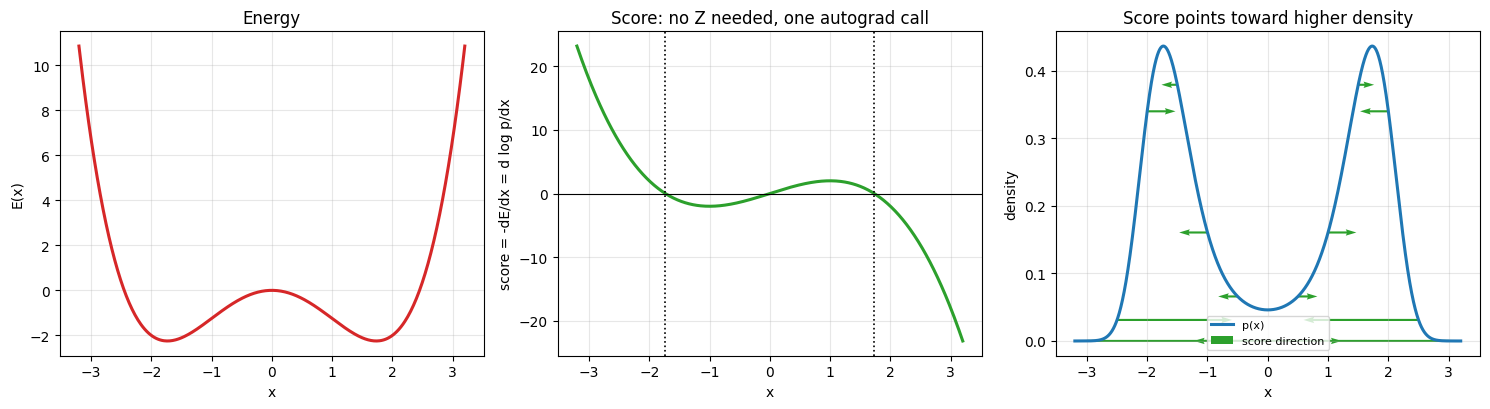

In [8]:
# ============================================================
# 図: スコアは確率の高い方向を指す
# ============================================================

xs_plot = torch.linspace(-3.2, 3.2, 400)
xg = xs_plot.clone().requires_grad_(True)
energy_1d(xg).sum().backward()
scores = -xg.grad.detach()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].plot(xs_plot, energy_1d(xs_plot), lw=2.2, color="tab:red")
axes[0].set_xlabel("x")
axes[0].set_ylabel("E(x)")
axes[0].set_title("Energy")

axes[1].plot(xs_plot, scores, lw=2.2, color="tab:green")
axes[1].axhline(0, color="k", lw=0.8)
for r in [-math.sqrt(3), math.sqrt(3)]:
    axes[1].axvline(r, color="k", ls=":", lw=1.2)
axes[1].set_xlabel("x")
axes[1].set_ylabel("score = -dE/dx = d log p/dx")
axes[1].set_title("Score: no Z needed, one autograd call")

mask_p = (xs >= -3.2) & (xs <= 3.2)
axes[2].plot(xs[mask_p], p0[mask_p], lw=2.2, color="tab:blue", label="p(x)")
qv = torch.linspace(-3.0, 3.0, 13)
qg = qv.clone().requires_grad_(True)
energy_1d(qg).sum().backward()
qs = -qg.grad.detach()
pv = torch.exp(-energy_1d(qv) - log_Z0)
axes[2].quiver(qv, pv, qs, torch.zeros_like(qs), color="tab:green",
               scale=30, width=0.005, label="score direction")
axes[2].set_xlabel("x")
axes[2].set_ylabel("density")
axes[2].set_title("Score points toward higher density")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

<a id="training"></a>
## 5. 最尤学習の勾配と「負のサンプル」

### 導出

$-\log p_\theta(x) = E_\theta(x) + \log Z_\theta$ を $\theta$ で微分します。
問題は第2項です。

$$\nabla_\theta \log Z_\theta
= \nabla_\theta \log \int e^{-E_\theta(x)}dx
= \frac{1}{Z_\theta}\int \big(-\nabla_\theta E_\theta(x)\big) e^{-E_\theta(x)}dx
= -\mathbb{E}_{x \sim p_\theta}\big[\nabla_\theta E_\theta(x)\big]$$

したがって

$$\boxed{\;\nabla_\theta \big(-\log p_\theta(x)\big)
= \underbrace{\nabla_\theta E_\theta(x)}_{\text{データでエネルギーを下げる}}
\;-\; \underbrace{\mathbb{E}_{x' \sim p_\theta}\big[\nabla_\theta E_\theta(x')\big]}_{\text{モデルのサンプルでエネルギーを上げる}}\;}$$

**意味**: 学習は「**データの場所を掘り下げ、モデルが今サンプルしてしまう場所を埋め戻す**」
という2つの力のつり合いです。第2項を**負のサンプル**（negative samples）と呼びます。

重要な点が2つあります。

1. **$Z$ そのものは要らない**。必要なのは $p_\theta$ からの**サンプル**だけ。
2. しかし $p_\theta$ からサンプルするのが、まさに難しい（$Z$ が分からないので）。

**194 が解くのはこの第2項です。** ランジュバン動力学はスコア $-\nabla_x E$ だけで
$p_\theta$ から（近似的に）サンプルします。第4節で「スコアが使える」と確かめたのが
ここで効いてきます。

### 負の項を落とすとどうなるか

まず、第2項を忘れて「データのエネルギーだけ下げる」とどうなるかを測ります。

**予想**: エネルギーが一様に下がり続けるだけで、分布を学ばない。
ただし定数シフトは分布を変えない（第2節）ので、
**データと他の場所のエネルギー差**が開けば学習にはなるはず。

In [9]:
# ============================================================
# 目標分布と格子（2次元なので Z を厳密に計算できる）
# ============================================================

MUS = np.array([[-2.0, -2.0], [2.0, 2.0], [-2.0, 2.0], [2.0, -2.0]])
SD = 0.5

def sample_gmm2d(n, seed=0):
    r = np.random.default_rng(seed)
    k = r.integers(0, 4, n)
    return (MUS[k] + r.standard_normal((n, 2)) * SD).astype(np.float32)

def logsumexp_np(a, axis):
    m = a.max(axis=axis, keepdims=True)
    return (m + np.log(np.exp(a - m).sum(axis=axis, keepdims=True))).squeeze(axis)

def gmm2d_logpdf(x):
    comps = [-0.5 * ((x - m) ** 2).sum(-1) / SD**2 - np.log(2 * np.pi * SD**2)
             for m in MUS]
    return logsumexp_np(np.stack(comps, -1), axis=-1) + np.log(0.25)

X2_train = sample_gmm2d(8000, seed=0)
X2_test = sample_gmm2d(4000, seed=1)
NLL_LB = float(-gmm2d_logpdf(X2_test).mean())
print(f"真の分布の test NLL（到達可能な下限）: {NLL_LB:.4f}")

K2, LO, HI = 128, -5.0, 5.0
g2 = torch.linspace(LO, HI, K2)
CELL = float((HI - LO) / (K2 - 1)) ** 2
G2X, G2Y = torch.meshgrid(g2, g2, indexing="ij")
GRID2 = torch.stack([G2X.reshape(-1), G2Y.reshape(-1)], -1)
print(f"格子: {K2}x{K2} = {GRID2.shape[0]:,} 点、セル面積 {CELL:.6f}")
print("2次元だから log Z を logsumexp で厳密に出せる。これが本章の実験台。")


class EnergyNet(nn.Module):
    # 任意のスカラー関数。可逆性もヤコビアンも要らない
    def __init__(self, d=2, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


def log_partition(E_net):
    # log Z = log sum exp(-E) + log(cell area)
    return torch.logsumexp(-E_net(GRID2), 0) + math.log(CELL)

真の分布の test NLL（到達可能な下限）: 2.8275
格子: 128x128 = 16,384 点、セル面積 0.006200
2次元だから log Z を logsumexp で厳密に出せる。これが本章の実験台。


In [10]:
# ============================================================
# 負の項を落とすと崩壊する
# ============================================================

torch.manual_seed(1)
E_bad = EnergyNet()
opt_bad = torch.optim.Adam(E_bad.parameters(), lr=1e-3)
X2t = torch.tensor(X2_train)

collapse_rows = []
for step in range(1, 601):
    loss = E_bad(X2t).mean()          # データのエネルギーだけ下げる（負の項なし）
    opt_bad.zero_grad()
    loss.backward()
    opt_bad.step()
    if step in (1, 100, 300, 600):
        with torch.no_grad():
            e_data = float(E_bad(X2t).mean())
            e_grid = float(E_bad(GRID2).mean())
            lz = float(log_partition(E_bad))
        collapse_rows.append((step, e_data, e_grid, lz))
        print(f"step {step:4d}: E(データ) {e_data:+14.2f}  E(格子全体) {e_grid:+14.2f}  "
              f"差 {e_grid - e_data:+14.2f}")

print()
print("-> エネルギーが一様に下がり続ける。しかも E(格子) - E(データ) が「負」のまま、")
print("   つまりデータ以外の場所のほうがさらに低い。差が開かないので分布を学んでいない。")
print("   第2節の「定数シフトは分布を変えない」が効いている: 全体を下げても無意味。")

step    1: E(データ)          -0.04  E(格子全体)          -0.09  差          -0.05


step  100: E(データ)       -1639.77  E(格子全体)       -2357.74  差        -717.97


step  300: E(データ)     -202045.92  E(格子全体)     -274515.03  差      -72469.11


step  600: E(データ)    -3781805.25  E(格子全体)    -4986750.50  差    -1204945.25

-> エネルギーが一様に下がり続ける。しかも E(格子) - E(データ) が「負」のまま、
   つまりデータ以外の場所のほうがさらに低い。差が開かないので分布を学んでいない。
   第2節の「定数シフトは分布を変えない」が効いている: 全体を下げても無意味。


In [11]:
# ============================================================
# 厳密な最尤学習（2次元なので log Z が計算できる）
# ============================================================

torch.manual_seed(1)
E_net = EnergyNet()
opt = torch.optim.Adam(E_net.parameters(), lr=2e-3)

t0 = time.time()
nll_hist, test_hist = [], []
for step in range(1, 1501):
    nll = E_net(X2t).mean() + log_partition(E_net)     # -log p = E(x) + log Z
    opt.zero_grad()
    nll.backward()
    opt.step()
    nll_hist.append(float(nll.detach()))
    if step % 50 == 0:
        with torch.no_grad():
            te = float(E_net(torch.tensor(X2_test)).mean() + log_partition(E_net))
        test_hist.append((step, te))

with torch.no_grad():
    nll_ebm = float(E_net(torch.tensor(X2_test)).mean() + log_partition(E_net))
    log_Z_final = float(log_partition(E_net))
    dens_ebm = torch.exp(-E_net(GRID2) - log_Z_final)
train_time = time.time() - t0

print(f"学習時間 {train_time:.1f}s")
print(f"EBM test NLL {nll_ebm:.4f} / 下限 {NLL_LB:.4f} -> 差 {nll_ebm - NLL_LB:.4f} nats")
print(f"学習した密度のグリッド積分 {float(dens_ebm.sum() * CELL):.5f}")
print(f"最終 log Z = {log_Z_final:+.4f}")
print()
print("比較（同じ目標分布・同じ下限 2.8275）:")
print(f"  191 RealNVP 交互マスク6層: 2.8779（下限まで 0.0504）")
print(f"  193 EBM（本章）           : {nll_ebm:.4f}（下限まで {nll_ebm - NLL_LB:.4f}）")

学習時間 17.7s
EBM test NLL 2.8309 / 下限 2.8275 -> 差 0.0033 nats
学習した密度のグリッド積分 1.00000
最終 log Z = +4.3565

比較（同じ目標分布・同じ下限 2.8275）:
  191 RealNVP 交互マスク6層: 2.8779（下限まで 0.0504）
  193 EBM（本章）           : 2.8309（下限まで 0.0033）


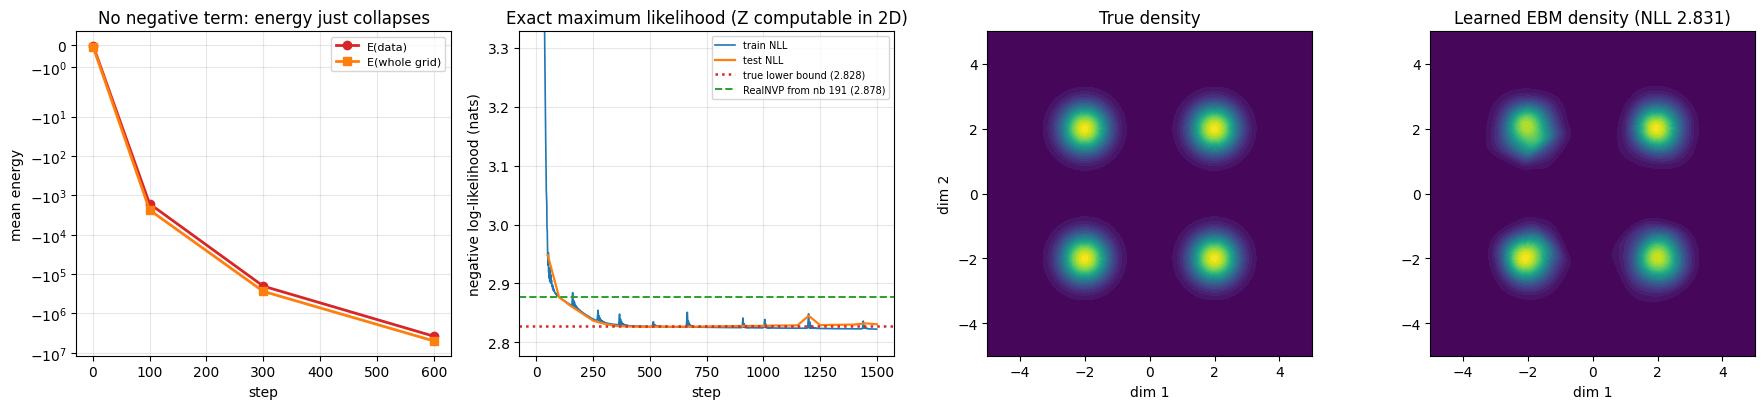

In [12]:
# ============================================================
# 図: 崩壊と、厳密な最尤学習の結果
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))

steps_c = [r[0] for r in collapse_rows]
axes[0].plot(steps_c, [r[1] for r in collapse_rows], "o-", lw=2,
             color="tab:red", label="E(data)")
axes[0].plot(steps_c, [r[2] for r in collapse_rows], "s-", lw=2,
             color="tab:orange", label="E(whole grid)")
axes[0].set_yscale("symlog")
axes[0].set_xlabel("step")
axes[0].set_ylabel("mean energy")
axes[0].set_title("No negative term: energy just collapses")
axes[0].legend(fontsize=8)

axes[1].plot(nll_hist, lw=1.2, color="tab:blue", label="train NLL")
axes[1].plot([s for s, _ in test_hist], [v for _, v in test_hist], lw=1.6,
             color="tab:orange", label="test NLL")
axes[1].axhline(NLL_LB, color="tab:red", ls=":", lw=1.8,
                label=f"true lower bound ({NLL_LB:.3f})")
axes[1].axhline(2.8779, color="tab:green", ls="--", lw=1.4,
                label="RealNVP from nb 191 (2.878)")
axes[1].set_xlabel("step")
axes[1].set_ylabel("negative log-likelihood (nats)")
axes[1].set_title("Exact maximum likelihood (Z computable in 2D)")
axes[1].set_ylim(NLL_LB - 0.05, NLL_LB + 0.5)
axes[1].legend(fontsize=7)

dens_true = np.exp(gmm2d_logpdf(np.stack([G2X.numpy(), G2Y.numpy()], -1)))
axes[2].contourf(G2X.numpy(), G2Y.numpy(), dens_true, levels=30, cmap="viridis")
axes[2].set_aspect("equal")
axes[2].set_title("True density")
axes[2].set_xlabel("dim 1")
axes[2].set_ylabel("dim 2")
axes[2].grid(False)

axes[3].contourf(G2X.numpy(), G2Y.numpy(),
                 dens_ebm.detach().numpy().reshape(K2, K2), levels=30, cmap="viridis")
axes[3].set_aspect("equal")
axes[3].set_title(f"Learned EBM density (NLL {nll_ebm:.3f})")
axes[3].set_xlabel("dim 1")
axes[3].grid(False)

plt.tight_layout()
plt.show()

### 読み取れること — 崩壊の形と、EBM の強さ

**崩壊（負の項なし）**: エネルギーは 600 ステップで $-3.8 \times 10^6$ まで落ちました。
しかも $E(\text{格子}) - E(\text{データ})$ が**負のまま**で、
データ以外の場所のほうがさらに低いです。
第2節の「定数シフトは分布を変えない」がそのまま効いていて、
**全体を下げる方向には学習の意味がありません**。
予想した「差が開けば学習になる」は起きませんでした。ネットは全体を下げるほうが
損失を速く下げられるので、差を開く動機がないのです。

**厳密な最尤学習**: 下限 2.8275 に対して EBM は差 **0.0033 nats** に到達しました。

| モデル | test NLL | 下限までの差 | 制約 |
|---|---|---|---|
| 191 RealNVP 交互6層 | 2.8779 | 0.0504 | 可逆・次元保存・三角ヤコビアン |
| **193 EBM（本章）** | **2.8309** | **0.0033** | なし（任意のスカラー関数） |

EBM が **15 倍近く下限に近い**です。これは予想どおりで、理由も明快です。
EBM は「密度の形」を直接ニューラルネットで作れるので、
**アーキテクチャの制約で表現力を失っていません**。
フローは可逆性のために層の形を制限したぶん、同じパラメータ規模で不利になります。

> ⚠️ **ただしこの比較は 2 次元だから成立しています。**
> EBM の 0.0033 は「$Z$ を 16,384 点の格子で厳密に計算できた」から出た数字です。
> $d=196$（191 の MNIST）では $Z$ が計算できないので、この学習法は使えません。
> **EBM は表現力で勝ち、計算可能性で負ける。** これが 6 系統の地図における
> EBM の位置です（196 で総括）。

In [13]:
# ============================================================
# 勾配の恒等式を数値で確かめる: ∇_θ log Z = -E_p[∇_θ E]
# ============================================================

# 左辺: autograd で ∇_θ log Z（格子で厳密に）
E_net.zero_grad()
log_partition(E_net).backward()
grad_exact = torch.cat([p.grad.reshape(-1).clone() for p in E_net.parameters()])

# 右辺: モデル分布 p_θ からサンプルして -E_p[∇_θ E] を推定
# （2次元なので格子上の多項分布から厳密にサンプルできる。高次元では不可能）
with torch.no_grad():
    probs = torch.exp(-E_net(GRID2) - log_partition(E_net)) * CELL
    probs = probs / probs.sum()
n_neg = 20_000
idx = torch.multinomial(probs, n_neg, replacement=True)
x_negative = GRID2[idx]

E_net.zero_grad()
(-E_net(x_negative).mean()).backward()
grad_mc = torch.cat([p.grad.reshape(-1).clone() for p in E_net.parameters()])

cos_sim = float(torch.dot(grad_exact, grad_mc)
                / (grad_exact.norm() * grad_mc.norm()))
norm_ratio = float(grad_mc.norm() / grad_exact.norm())

print(f"∇_θ log Z（autograd・格子で厳密）と -E_p[∇_θ E]（{n_neg:,} サンプル）の比較")
print(f"  コサイン類似度: {cos_sim:.6f}")
print(f"  ノルム比      : {norm_ratio:.6f}")
print()
print("-> 恒等式は成り立つ。ずれはモンテカルロ誤差だけ。")
print("   つまり「モデルからサンプルできれば Z なしで最尤学習できる」。")
print("   本章ではそのサンプリングを格子でやった（2次元限定）。")
print("   194 ではスコアだけを使うランジュバン動力学でこれを置き換える。")

∇_θ log Z（autograd・格子で厳密）と -E_p[∇_θ E]（20,000 サンプル）の比較
  コサイン類似度: 0.999997
  ノルム比      : 1.001953

-> 恒等式は成り立つ。ずれはモンテカルロ誤差だけ。
   つまり「モデルからサンプルできれば Z なしで最尤学習できる」。
   本章ではそのサンプリングを格子でやった（2次元限定）。
   194 ではスコアだけを使うランジュバン動力学でこれを置き換える。


### 194 への橋

本章で確定したことを並べると、次にやるべきことが一意に決まります。

| 確定 | 帰結 |
|---|---|
| $Z$ は計算できない（$d \ge 5$ で格子不能、$d=40$ で重点サンプリングも崩壊） | $Z$ を直接扱う道は閉じた |
| 最尤学習に必要なのは $Z$ ではなく $p_\theta$ からの**サンプル** | サンプリング法があればよい |
| スコア $\nabla_x \log p = -\nabla_x E$ は $Z$ なしで厳密に出る（自動微分1回） | **スコアだけでサンプリングできないか？** |

最後の問いに「できる」と答えるのが **194 ランジュバン動力学**です。

$$x_{t+1} = x_t + \frac{\epsilon}{2}\underbrace{\nabla_x \log p(x_t)}_{= -\nabla_x E(x_t)}
+ \sqrt{\epsilon}\, \eta_t, \qquad \eta_t \sim \mathcal{N}(0, I)$$

スコアの方向に登りながらノイズを足す、それだけです。
$\epsilon \to 0$、ステップ数 $\to \infty$ で $p$ からの正しいサンプルに収束します。
本章の第4節で「スコアは自動微分1回で厳密」と測ったので、この更新式は**実行できます**。

<a id="summary"></a>
## 6. まとめとチートシート

### EBM の定義と性質

| 項目 | 式 | 備考 |
|---|---|---|
| 密度 | $p_\theta(x) = e^{-E_\theta(x)} / Z_\theta$ | $E$ は任意のスカラー関数 |
| 分配関数 | $Z_\theta = \int e^{-E_\theta(x)}dx$ | **計算不能**（本章の主題） |
| 定数シフト | $E \to E + c$ で $p$ 不変 | $E$ の絶対値に意味はない |
| 密度比 | $p(x_1)/p(x_2) = e^{-(E(x_1)-E(x_2))}$ | $Z$ が消える |
| スコア | $\nabla_x \log p = -\nabla_x E$ | $Z$ が消える。**自動微分1回** |
| 最尤の勾配 | $\nabla_\theta E(x_{\text{data}}) - \mathbb{E}_{p_\theta}[\nabla_\theta E]$ | 第2項に負のサンプルが必要 |

### $Z$ を計算する3つの試みと限界（本章の実測）

| 方法 | コスト | 壊れる場所 |
|---|---|---|
| 格子で総当たり | $K^d$ | $K=50$ で $d=4$ が 100 MB、$d=5$ で断念 |
| 重点サンプリング | 一定だが分散が爆発 | $d=40$ で有効サンプル数 **1.5 / 200,000** |
| 解析積分 | — | $E$ が2次式（= ガウス）など特別な形だけ |

$d=196$（MNIST 14x14）なら格子は $10^{333}$ 点。選択肢になりません。

### 本章で測った数値

| 項目 | 値 |
|---|---|
| 定数シフト $c = 0 / +100 / -37.5$ での $p(0)$ | 全て 0.046047（完全同一） |
| 密度の最大点の絶対値（数値）vs $\sqrt{3}$（解析） | 1.7322 vs 1.7321 |
| 密度比：$E$ の差から vs $Z$ 経由 | 差 $10^{-9}$ 以下 |
| スコア：$-dE/dx$ vs $d\log p/dx$ の数値微分 | 5 点で全て一致 |
| 負の項なしの学習（600 step） | $E(\text{データ}) = -3.8\times10^6$、差は開かない |
| 厳密最尤の EBM（2次元） | test NLL 2.8309（下限 2.8275、差 **0.0033**） |
| 同条件の RealNVP（191） | test NLL 2.8779（差 0.0504） |
| 勾配の恒等式の確認 | コサイン類似度 0.999997 |

### 他の生成モデルとの関係

| モデル | 正規化 | 代償 |
|---|---|---|
| **EBM** | **できない**（$Z$ 不能） | サンプリングと学習が重い。表現力は最大 |
| フロー（190-191） | 構造で保証（可逆・ヤコビアン） | アーキテクチャが制限される |
| VAE（35-38） | 回避（ELBO = 下界） | 尤度が等号でない |
| 拡散（37-45） | 回避（変分下界） | 尤度が等号でない。ただし品質は最高水準 |
| 自己回帰（46, 123-124） | 連鎖律で各条件付き分布を正規化 | 生成が逐次的 |

**EBM は「正規化を諦める」という4番目の選択肢**です。
そして 195 で分かるとおり、拡散モデルは**EBM のサンプリングを賢くしたもの**として
読めます。本章の「スコアが $Z$ なしで出る」が、その接続点です。

<a id="quiz"></a>
## 7. 自己評価クイズ

### Q1: 「$Z$ はただの定数」はどこが間違いか

**問題**: 「$Z$ は $x$ に依存しない定数だから、最尤学習では無視できる」。
この主張の誤りを数式で指摘してください。

<details>
<summary>答えを見る</summary>

$Z_\theta$ は $x$ については定数ですが、**$\theta$ については定数ではありません**。
最尤学習は $\theta$ についての最適化なので、消えません。

$$\nabla_\theta \log Z_\theta = -\mathbb{E}_{x \sim p_\theta}[\nabla_\theta E_\theta(x)] \ne 0$$

無視すると「データのエネルギーだけ下げる」学習になり、本章の実測では
600 ステップで $E(\text{データ})$ が $-3.8\times10^6$ まで落ちる一方、
$E(\text{格子全体}) - E(\text{データ})$ は**負のまま**でした。
全体を一様に下げるのが最も速く損失を下げる道だからです。

そして第2節のとおり、**定数シフトは分布を変えません**。
つまりこの学習は「分布を何も変えないまま損失だけ下げる」という
完全に無意味な最適化です。

**スコア** $\nabla_x \log p$ では $Z$ が本当に消えます（$x$ の微分だから）。
「$x$ の微分では消える、$\theta$ の微分では消えない」が正しい切り分けです。
</details>

---

### Q2: 重点サンプリングの誤差の符号

**問題**: 本章の実測で、重点サンプリングによる $\log Z$ の推定誤差は
**常に負**（過小推定）でした。なぜ符号が偏るのか、そしてそれが
報告上なぜ危険なのかを説明してください。

<details>
<summary>答えを見る</summary>

**符号の偏り**: 重み $w = e^{-E}/q$ の分布は次元が上がるほど極端に歪み、
和がごく少数の最大重みに支配されます（本章では $d=40$ で有効サンプル数 1.5）。
提案分布 $q$ が重みの大きい領域をほとんど引けないので、
その領域の寄与が和から落ちます。落ちるのは常に**正の量**なので、
$Z$ の推定は**下に偏ります**。

$\hat{Z}$ は不偏推定量ですが、$\log \hat{Z}$ は Jensen の不等式により
$\mathbb{E}[\log \hat Z] \le \log \mathbb{E}[\hat Z] = \log Z$ で、
**対数を取ると下に偏る**のも同じ方向です。

**危険な理由**: 対数尤度は

$$\log p(x) = -E(x) - \log Z$$

なので、$\log Z$ を過小推定すると $\log p(x)$ を**過大評価**します。
つまり「モデルが実際より良く見える」方向に間違えます。
EBM の尤度を重点サンプリングで報告している結果は、
**楽観側にバイアスしている**と疑うべきです（有効サンプル数を併記しないと検証できない）。
</details>

---

### Q3: EBM がフローに勝った理由と、勝てない条件

**問題**: 本章の EBM は下限まで 0.0033 nats、191 の RealNVP は 0.0504 nats でした。
EBM が勝った理由と、この比較が成立する条件を述べてください。

<details>
<summary>答えを見る</summary>

**勝った理由**: EBM は密度の形を**任意のスカラー関数**で直接作れます。
RealNVP は可逆性・次元保存・三角ヤコビアンのために層の形がカップリングに
制限されており、同じパラメータ規模で表現力を失っています。
EBM に残る制約は「$Z$ が有限」だけで、これは実用上ほぼ制約になりません。

**成立する条件**: この 0.0033 は **$d=2$ で $Z$ を $128^2 = 16{,}384$ 点の格子で
厳密に計算できた**から出た数字です。本章第3節のとおり、$d=5$ で既に格子が破綻します。
$d=196$（191 の MNIST）では

- $Z$ を計算できない → 本章の学習法が使えない
- 負のサンプルを格子から引けない → 恒等式も直接使えない

ので、EBM の**実装可能性**が消えます。フローは $d=196$ で実際に動きました
（2.6552 bits/dim）。

**まとめると**: EBM は表現力で勝ち、計算可能性で負けます。
194（ランジュバン）が計算可能性の側を埋めにいき、どこまで埋まるかを測ります。
</details>

---

### Q4: 負のサンプルの質が悪いと何が起きるか

**問題**: 194 でランジュバン動力学を使って負のサンプルを得ます。もしその
サンプリングが**不十分**（ステップ数が足りず $p_\theta$ に収束していない）だと、
学習にどんな影響が出ると予想しますか。

<details>
<summary>答えを見る</summary>

（本章では未検証の**予想**です。194 で測ります。）

勾配の第2項は $\mathbb{E}_{x' \sim p_\theta}[\nabla_\theta E(x')]$ で、
「モデルが確率を置いてしまっている場所を埋め戻す」力です。
サンプラーがその場所に届かないと、**埋め戻しが起きません**。

予想される症状:

- サンプラーが初期点の近傍しか探索しないと、そこだけ埋め戻され、
  **探索されない場所のエネルギーが下がり放題**になる。
  第5節の崩壊の「局所版」が起きる。
- エネルギーの形が鋭くなるほどサンプラーが動きにくくなり、
  **学習が進むほどサンプリングが難しくなる**という悪循環がありうる。
- 結果として、尤度は良く見えるのにサンプルが汚い（またはその逆）という
  不整合が出る。

この「サンプラーの質が学習の質を決める」という構造が、EBM が
フローや拡散に比べて扱いにくい最大の理由です。194 で実測します。
</details>

In [14]:
# ============================================================
# 最終サマリ
# ============================================================

print("=" * 72)
print("Notebook 193 完了: エネルギーベースモデルの定式化")
print("=" * 72)
print(f'''
【定義】 p(x) = exp(-E(x)) / Z,  Z = ∫ exp(-E(x)) dx

  定数シフトの不変性: c = 0 / +100 / -37.5 で p(0) = ''' + ", ".join(
    f"{r[3]:.6f}" for r in shift_rows) + f'''
  （log Z は {shift_rows[0][1]:+.4f} / {shift_rows[1][1]:+.4f} / {shift_rows[2][1]:+.4f} と動くのに密度は同一）
  密度の最大点 |x| = {abs(float(xs[int(torch.argmax(p0))])):.4f} = エネルギー極小 sqrt(3) = {math.sqrt(3):.4f}

【分配関数の壁】

  格子で総当たり（K={K_GRID}）:
''' + "\n".join(
    f"    d={r[0]}: {r[1]:>12,} 点  メモリ {r[3]:8.1f} MB"
    + ("  -> 実行不能" if r[2] is None else f"  {r[2]:.2f}s") for r in grid_rows) + f'''
    d=196（MNIST 14x14）: 10^{196 * math.log10(K_GRID):.0f} 点

  重点サンプリング（20万サンプル固定）:
''' + "\n".join(
    f"    d={r[0]:3d}: 誤差 {r[1]-r[2]:+8.4f}  有効サンプル数 {r[3]:9.1f}/200000"
    for r in is_rows) + f'''
    -> 誤差は常に負（過小推定）= 尤度を過大評価する危険な方向

【Z を知らなくても出せるもの】

  密度比 p(0)/p(1.8): E の差から {ratio_from_E:.8f} / Z 経由 {ratio_with_Z:.8f}
  スコア -dE/dx と d log p/dx の数値微分: 5点すべて一致
  -> log Z は x に依存しないので微分で消える。自動微分1回で厳密。

【最尤学習の勾配】

  ∇_θ(-log p) = ∇_θ E(データ) - E_{{p_θ}}[∇_θ E]
  恒等式の確認: コサイン類似度 {cos_sim:.6f}  ノルム比 {norm_ratio:.6f}

  負の項を落とすと崩壊:
''' + "\n".join(
    f"    step {r[0]:4d}: E(データ) {r[1]:+14.2f}  E(格子) - E(データ) {r[2]-r[1]:+14.2f}"
    for r in collapse_rows) + f'''
    -> 一様に下がるだけで差が開かない。定数シフトは分布を変えないので無意味。

【2次元での厳密な最尤学習（Z が計算できる唯一の条件）】

  EBM      test NLL {nll_ebm:.4f}  （下限 {NLL_LB:.4f} まで {nll_ebm - NLL_LB:.4f} nats）
  RealNVP  test NLL 2.8779  （下限まで 0.0504 nats、191 の実測）
  学習した密度のグリッド積分 {float(dens_ebm.sum() * CELL):.5f}
  学習時間 {train_time:.1f}s

  -> EBM が約 15 倍下限に近い。アーキテクチャの制約がないため。
     ただしこれは d=2 で Z を {GRID2.shape[0]:,} 点の格子で計算できたから出た数字。
     d=196 ではこの学習法は使えない。表現力で勝ち、計算可能性で負ける。

【次の章へ】
  194 ランジュバン動力学: スコア -∇_x E だけで p_θ からサンプルする。
       これで最尤の第2項（負のサンプル）を高次元でも作れるようになる。
''')
print("=" * 72)

Notebook 193 完了: エネルギーベースモデルの定式化

【定義】 p(x) = exp(-E(x)) / Z,  Z = ∫ exp(-E(x)) dx

  定数シフトの不変性: c = 0 / +100 / -37.5 で p(0) = 0.046047, 0.046047, 0.046047
  （log Z は +3.0781 / -96.9219 / +40.5781 と動くのに密度は同一）
  密度の最大点 |x| = 1.7322 = エネルギー極小 sqrt(3) = 1.7321

【分配関数の壁】

  格子で総当たり（K=50）:
    d=1:           50 点  メモリ      0.0 MB  0.00s
    d=2:        2,500 点  メモリ      0.0 MB  0.00s
    d=3:      125,000 点  メモリ      1.5 MB  0.00s
    d=4:    6,250,000 点  メモリ    100.0 MB  0.08s
    d=5:  312,500,000 点  メモリ   6250.0 MB  -> 実行不能
    d=196（MNIST 14x14）: 10^333 点

  重点サンプリング（20万サンプル固定）:
    d=  1: 誤差  +0.0018  有効サンプル数   95578.7/200000
    d=  2: 誤差  -0.0020  有効サンプル数   45631.7/200000
    d=  5: 誤差  -0.0141  有効サンプル数    5191.6/200000
    d= 10: 誤差  -0.0928  有効サンプル数     192.0/200000
    d= 20: 誤差  -0.8461  有効サンプル数       8.6/200000
    d= 40: 誤差  -7.2163  有効サンプル数       1.5/200000
    -> 誤差は常に負（過小推定）= 尤度を過大評価する危険な方向

【Z を知らなくても出せるもの】

  密度比 p(0)/p(1.8): E の差から 0.10692795 / Z 経由 0.10692798
  スコア -dE/d